
## Analise exploratoria dos dados CWRU

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.io import loadmat, whosmat


def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Nao encontrei pyproject.toml e data nos diretorios acima do kernel.")


ROOT = find_project_root(Path.cwd())
DATA_DIR = ROOT / "data"
CSV_PATH = DATA_DIR / "feature_time_48k_2048_load_1.csv"
NPZ_PATH = DATA_DIR / "CWRU_48k_load_1_CNN_data.npz"
RAW_DIR = DATA_DIR / "raw"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)

## Carregamento e verificacao dos arquivos

In [3]:
for path in (CSV_PATH, NPZ_PATH, RAW_DIR):
    if not path.exists():
        raise FileNotFoundError(f"Caminho esperado nao encontrado: {path}")

features = pd.read_csv(CSV_PATH)
with np.load(NPZ_PATH, allow_pickle=False) as archive:
    print("Arrays no NPZ:", archive.files)
    if not {"data", "labels"}.issubset(archive.files):
        raise ValueError("O NPZ precisa conter os arrays 'data' e 'labels'.")
    images = np.asarray(archive["data"], dtype=np.float32)
    labels = np.asarray(archive["labels"]).astype(str)

print(f"CSV: {features.shape[0]} linhas, {features.shape[1]} colunas")
print(f"NPZ data: {images.shape}, dtype={images.dtype}")
print(f"NPZ labels: {labels.shape}, dtype={labels.dtype}")
display(features.head())

Arrays no NPZ: ['data', 'labels']
CSV: 2300 linhas, 10 colunas
NPZ data: (4600, 32, 32), dtype=float32
NPZ labels: (4600,), dtype=<U8


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,fault
0,0.35986,-0.41890,0.017840,0.122746,0.124006,-0.118571,-0.042219,2.901946,6.950855,Ball_007_1
1,0.46772,-0.36111,0.022255,0.132488,0.134312,0.174699,-0.081548,3.482334,6.035202,Ball_007_1
2,0.46855,-0.43809,0.020470,0.149651,0.151008,0.040339,-0.274069,3.102819,7.376926,Ball_007_1
3,0.58475,-0.54303,0.020960,0.157067,0.158422,-0.023266,0.134692,3.691097,7.558387,Ball_007_1
4,0.44685,-0.57891,0.022167,0.138189,0.139922,-0.081534,0.402783,3.193561,6.312085,Ball_007_1


## Qualidade dos dados e classes
## O CSV contem features agregadas; o NPZ contem matrizes 32x32 e seus rotulos.

In [4]:
print("Valores ausentes por coluna:")
display(features.isna().sum().rename("missing"))

numeric_columns = features.select_dtypes(include="number").columns.tolist()
print("Resumo estatistico das features numericas:")
display(features[numeric_columns].describe().T)

csv_counts = features["fault"].value_counts().sort_index()
npz_counts = pd.Series(labels).value_counts().sort_index()
print("Contagem de classes no CSV:")
display(csv_counts.rename("amostras_csv"))
print("Contagem de classes no NPZ:")
display(npz_counts.rename("amostras_npz"))

Valores ausentes por coluna:


max         0
min         0
mean        0
sd          0
rms         0
skewness    0
kurtosis    0
crest       0
form        0
fault       0
Name: missing, dtype: int64

Resumo estatistico das features numericas:


,count,mean,std,min,25%,50%,75%,max
max,2300.0,1.575079,1.578422,0.157300,0.456398,0.794510,2.278425,6.825900
min,2300.0,-1.550994,1.602706,-6.292600,-2.174975,-0.733700,-0.426987,-0.160220
mean,2300.0,0.015711,0.006469,0.003246,0.011236,0.013730,0.018638,0.038386
sd,2300.0,0.341601,0.305279,0.059140,0.135506,0.188551,0.555589,1.256577
rms,2300.0,0.342289,0.304813,0.061067,0.136374,0.190662,0.555671,1.256311
skewness,2300.0,-0.042251,0.180774,-1.089928,-0.103426,-0.002466,0.061093,1.059512
kurtosis,2300.0,2.664444,4.411096,-0.803795,-0.015164,0.816970,3.902286,30.385326
crest,2300.0,4.173130,1.148349,2.428511,3.260382,3.921650,4.815876,8.821577
form,2300.0,26.544769,29.209702,3.484429,7.413359,13.122811,39.911894,313.742612


Contagem de classes no CSV:


fault
Ball_007_1    230
Ball_014_1    230
Ball_021_1    230
IR_007_1      230
IR_014_1      230
IR_021_1      230
Normal_1      230
OR_007_6_1    230
OR_014_6_1    230
OR_021_6_1    230
Name: amostras_csv, dtype: int64

Contagem de classes no NPZ:


Ball_007    460
Ball_014    460
Ball_021    460
IR_007      460
IR_014      460
IR_021      460
Normal      460
OR_007      460
OR_014      460
OR_021      460
Name: amostras_npz, dtype: int64

## Distribuicao das features por falha

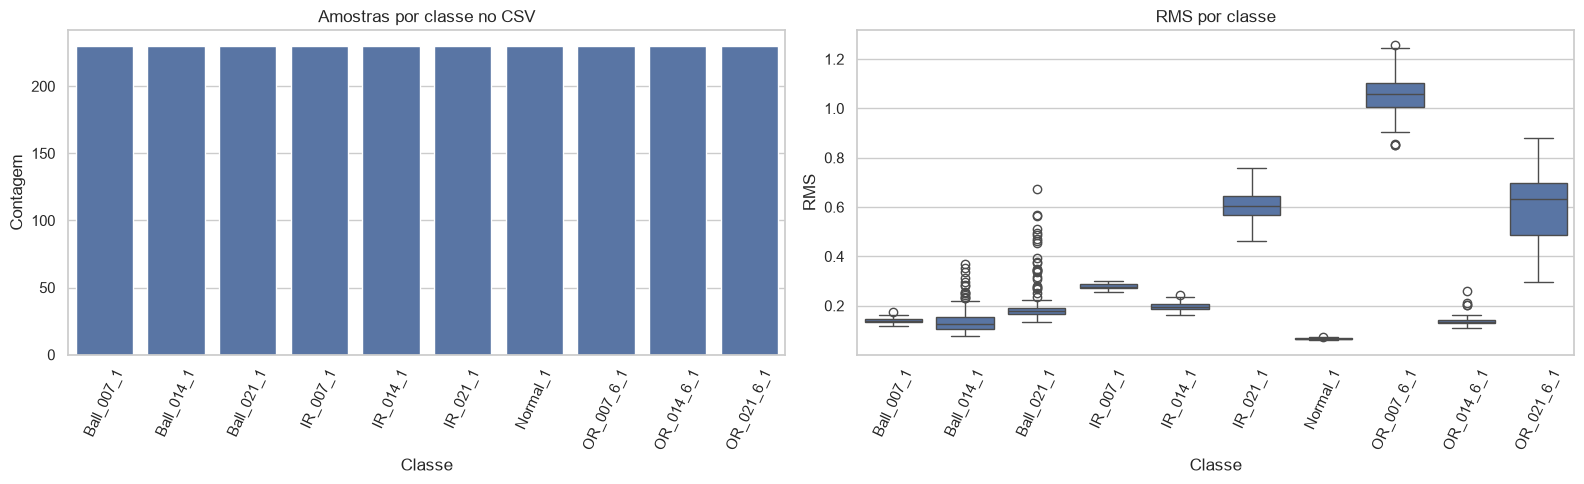

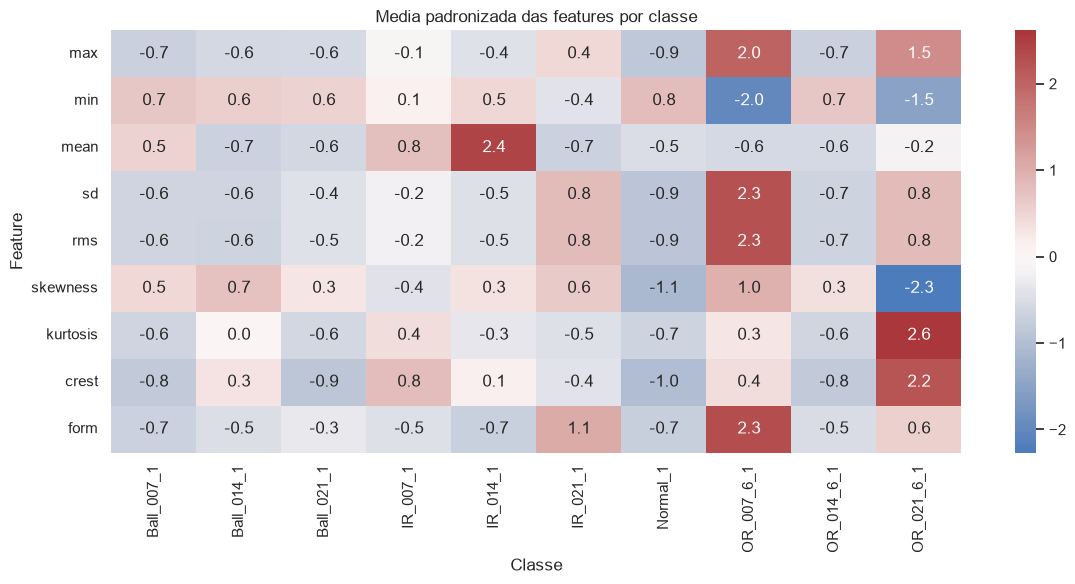

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=features, x="fault", order=csv_counts.index, ax=axes[0])
axes[0].set(title="Amostras por classe no CSV", xlabel="Classe", ylabel="Contagem")
axes[0].tick_params(axis="x", rotation=65)

sns.boxplot(data=features, x="fault", y="rms", order=csv_counts.index, ax=axes[1])
axes[1].set(title="RMS por classe", xlabel="Classe", ylabel="RMS")
axes[1].tick_params(axis="x", rotation=65)
figure.tight_layout()
plt.show()


mean_features = features.groupby("fault")[numeric_columns].mean()
standardized_means = (mean_features - mean_features.mean()) / mean_features.std().replace(0, 1)
figure, axis = plt.subplots(figsize=(12, 6))
sns.heatmap(standardized_means.T, cmap="vlag", center=0, annot=True, fmt=".1f", ax=axis)
axis.set(title="Media padronizada das features por classe", xlabel="Classe", ylabel="Feature")
figure.tight_layout()
plt.show()


## Visualizacao das matrizes do NPZ
### As amostras do NPZ sao matrizes 32x32. O flatten para 1024 valores e a entrada usada
### pelo Conv1D do `main.py`; aqui mostramos a matriz original para inspecao.

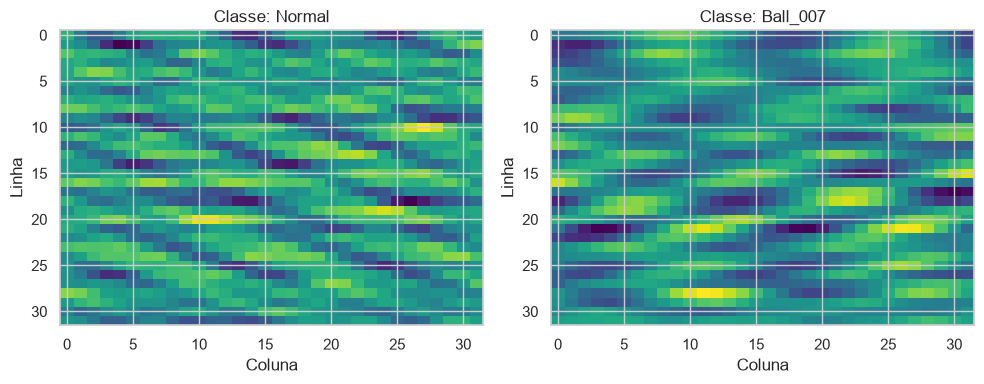

Faixa global do NPZ: -6.292600154876709 a 6.825900077819824
Media e desvio padrao: 0.015710795298218727 0.45802339911460876


In [6]:
if images.ndim != 3 or images.shape[0] != labels.shape[0]:
    raise ValueError(f"Formato inesperado para data/labels: {images.shape}, {labels.shape}")

example_labels = ["Normal", "Ball_007"]
figure, axes = plt.subplots(1, len(example_labels), figsize=(10, 4))
for axis, label in zip(axes, example_labels):
    matches = np.flatnonzero(labels == label)
    if len(matches) == 0:
        axis.set_visible(False)
        print(f"Rotulo {label!r} nao encontrado no NPZ.")
        continue
    index = int(matches[0])
    image = images[index]
    axis.imshow(image, aspect="auto", cmap="viridis")
    axis.set(title=f"Classe: {labels[index]}", xlabel="Coluna", ylabel="Linha")
figure.tight_layout()
plt.show()

print("Faixa global do NPZ:", float(images.min()), "a", float(images.max()))
print("Media e desvio padrao:", float(images.mean()), float(images.std()))

## Inventario dos sinais brutos MAT
## Inspeciona os metadados e carrega somente as variaveis DE usadas na analise.

In [7]:
mat_files = sorted(RAW_DIR.glob("*.mat"))
raw_inventory = []
for mat_path in mat_files:
    variable_metadata = whosmat(mat_path)
    signal_keys = [name for name, _, _ in variable_metadata if name.endswith("_DE_time")]
    contents = loadmat(mat_path, variable_names=signal_keys) if signal_keys else {}
    for key in signal_keys:
        signal = np.asarray(contents[key]).squeeze()
        raw_inventory.append(
            {
                "file": mat_path.name,
                "signal": key,
                "samples": signal.size,
                "mean": float(signal.mean()),
                "std": float(signal.std()),
            }
        )

raw_summary = pd.DataFrame(raw_inventory)
display(raw_summary)
print(f"Arquivos MAT encontrados: {len(mat_files)}")

,file,signal,samples,mean,std
0,B007_1_123.mat,X123_DE_time,487384,0.019031,0.140115
1,B014_1_190.mat,X190_DE_time,486224,0.011370,0.147546
2,B021_1_227.mat,X227_DE_time,486804,0.011884,0.213094
3,IR007_1_110.mat,X110_DE_time,486224,0.020731,0.277919
4,IR014_1_175.mat,X217_DE_time,489125,0.031239,0.195394
5,IR014_1_175.mat,X175_DE_time,381890,0.018623,0.260865
6,IR021_1_214.mat,X214_DE_time,485063,0.011308,0.608369
7,OR007_6_1_136.mat,X136_DE_time,486804,0.012112,1.060640
8,OR014_6_1_202.mat,X202_DE_time,484483,0.012139,0.136573
9,OR021_6_1_239.mat,X239_DE_time,489125,0.014577,0.619140


Arquivos MAT encontrados: 10
